In [ ]:
import xarray as xr
import numpy as np
import pandas as pd
import os
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
import timm
from scipy.ndimage import zoom
from sklearn.model_selection import train_test_split, StratifiedKFold
import copy
from contextlib import redirect_stdout
import json
import matplotlib.pyplot as plt
import seaborn as sns
from functions_for_goes import crop_goes_to_latlon_box, convert_radiance_to_brightness_temp
from judge_goes import preprocess_data, setup_region_parameters

# Manually label a small dataset of GOES images for fine-tuning

## Functions

In [2]:
def load_and_prepare_goes_data(date, time):
    ts = pd.to_datetime(date + time)

    lat_bounds, lon_bounds, times = setup_region_parameters(region='SEP')
    month = date[4:6]
    data_dir=f'/home/jmayer/Object_Data/GOES19/2025/{month}/'

    print('.' * 85)
    print(f"Processing date {date} time {time}...")
    
    # Load and crop GOES data
    print("Loading C11 data...")
    with xr.open_dataset(f'{data_dir}/goes19_C11_RadF_{date}_{time}.nc') as ds:
        ds = convert_radiance_to_brightness_temp(ds)
        ds_11_cropped = crop_goes_to_latlon_box(ds, lat_bounds, lon_bounds)

    print("Loading C14 data...")
    with xr.open_dataset(f'{data_dir}/goes19_C14_RadF_{date}_{time}.nc') as ds:
        ds = convert_radiance_to_brightness_temp(ds)
        ds_14_cropped = crop_goes_to_latlon_box(ds, lat_bounds, lon_bounds)

    print("Loading C15 data...")
    with xr.open_dataset(f'{data_dir}/goes19_C15_RadF_{date}_{time}.nc') as ds:
        ds = convert_radiance_to_brightness_temp(ds)
        ds_15_cropped = crop_goes_to_latlon_box(ds, lat_bounds, lon_bounds)

    print("Loading COD data...")
    with xr.open_dataset(f'{data_dir}/goes19_COD2KMF_{date}_{time}.nc') as ds:
        ds_COD_cropped = crop_goes_to_latlon_box(ds, lat_bounds, lon_bounds)

    return ds_11_cropped, ds_14_cropped, ds_15_cropped, ds_COD_cropped

In [ ]:
# Replace your matplotlib setup with:
import matplotlib
matplotlib.use('Agg')  # Use non-interactive backend
%matplotlib inline

# Then use the simplified non-interactive labeler
class SimpleGOESLabeler:
    def __init__(self, image_data, scene_params, datetime, cod, class_names, save_path='labeled_goes_data.nc'):
        self.image_data = image_data
        self.scene_params = scene_params
        self.datetime = datetime
        self.cod = cod
        self.class_names = class_names
        self.save_path = save_path
        self.results = []  # List to store labeled data
        self.load_existing_unique_ids()
        self.unique_id = self.create_unique_id()
        
    def load_existing_unique_ids(self):
        """Load existing labels from netCDF file"""
        if os.path.exists(self.save_path):
            with xr.open_dataset(self.save_path) as ds:
                self.existing_unique_ids = ds.unique_id.values
        else:
            self.existing_unique_ids = None

    def create_unique_id(self):
        """Create a unique identifier for the current sample"""
        uid = (f"{pd.to_datetime(self.datetime).strftime('%Y%m%d%H%M')}_"
               f"{self.scene_params['y_idx']}_"
               f"{self.scene_params['x_idx']}")
        return uid

    def check_if_already_labeled(self):
        """Check if a sample with the given unique_id has already been labeled"""
        if self.existing_unique_ids is None:
            return False
        return self.unique_id in self.existing_unique_ids

    def save_labels_to_file(self, label_idx):
        """Save labels to netCDF file with incremental updates"""

        new_ds = xr.Dataset({
            'unique_id': (['sample'], [self.unique_id]),
            'datetime': (['sample'], [pd.to_datetime(self.datetime)]),
            'y_idx': (['sample'], [self.scene_params['y_idx']]),
            'x_idx': (['sample'], [self.scene_params['x_idx']]),
            'lat_mid': (['sample'], [self.scene_params['lat_mid']]),
            'lon_mid': (['sample'], [self.scene_params['lon_mid']]),
            'ice_flag': (['sample'], [self.scene_params['ice_flag']]),
            'label': (['sample'], [label_idx]),
            'class_name': (['sample'], [self.class_names[label_idx]]),
            'image_data': (['sample', 'channel', 'y', 'x'], [self.image_data])
            }, 
            coords={'sample': [self.scene_params['image_idx']]}
        )
        
        # Save or append to file
        if os.path.exists(self.save_path):
            # Load existing and concatenate
            with xr.open_dataset(self.save_path) as existing_ds:
                # Remove existing label for this image if it exists
                if self.check_if_already_labeled():
                    existing_ds.load()
                    existing_ds = existing_ds.where(existing_ds.unique_id != self.unique_id, drop=True)

                combined_ds = xr.concat([existing_ds, new_ds], dim='sample')
                combined_ds.to_netcdf(self.save_path)
        else:
            # Save new file
            new_ds.to_netcdf(self.save_path)
            
        print(f"Saved new label to {self.save_path}")
    
    def display_image_to_label(self, img_idx):
        """Display an image for labeling"""
        fig, axes = plt.subplots(1, 4, figsize=(15, 5))
        
        idx = img_idx
        current_image = self.image_data

        # Display COD channel
        axes[0].imshow(current_image[3], vmax=1, cmap='Greys_r')
        axes[0].set_title('COD Channel')
        axes[0].axis('off')
        
        # Display BT channel
        axes[1].imshow(current_image[2], vmax=1, cmap='Greys')
        axes[1].set_title('BT Ch14')
        axes[1].axis('off')

        # Display RGB composite
        rgb_channels = current_image[0:3]
        rgb_image = np.zeros((128, 128, 3))
        for j in range(3):
            ch = rgb_channels[j]
            rgb_image[:, :, j] = ch
        axes[2].imshow(rgb_image)
        axes[2].set_title('RGB Composite')
        axes[2].axis('off')

        # Show zoomed out COD image for context
        cod = self.cod
        y_idx_not_zoomed = self.scene_params['y_idx']//2
        x_idx_not_zoomed = self.scene_params['x_idx']//2
        img_buffer = 400
        
        y_start = max(0, y_idx_not_zoomed - img_buffer)
        y_end = min(cod.shape[0], y_idx_not_zoomed + img_buffer)
        x_start = max(0, x_idx_not_zoomed - img_buffer)
        x_end = min(cod.shape[1], x_idx_not_zoomed + img_buffer)
        
        axes[3].imshow(cod[y_start:y_end, x_start:x_end], vmax=40, vmin=0, cmap='Greys_r')
        # plot box where image is
        x_box = min(x_idx_not_zoomed-32, img_buffer-32)
        y_box = min(y_idx_not_zoomed-32, img_buffer-32)
        axes[3].plot([x_box, x_box + 64, x_box + 64, x_box, x_box],
                     [y_box, y_box, y_box + 64, y_box + 64, y_box],
                     color='red', linewidth=2)
        axes[3].set_title('COD Context')
        axes[3].axis('off')
        
        # Add title with location info
        lat = self.scene_params['lat_mid']
        lon = self.scene_params['lon_mid']
        title = f"Image #{idx}: Datetime {self.datetime}, Lat {lat:.1f}°, Lon {lon:.1f}°"
        
        # Check if already labeled
        existing_label = self.check_if_already_labeled()         
        if existing_label:
            title += f"\n[Current: {self.class_names[existing_label]}]"
            fig.patch.set_facecolor('lightgreen')
        
        fig.suptitle(title, fontsize=12)
        plt.tight_layout()
        plt.show()
        plt.close()
        
    def label_single_image(self, img_idx):
        """Label a single image interactively"""
        self.display_image_to_label(img_idx)
        
        print("\nClass options:")
        for i, class_name in enumerate(self.class_names):
            print(f"{i}: {class_name}")
        print("s: Skip image")
        print("d: delete label if exists")
        print("q: Quit labeling")
        
        while True:
            try:
                user_input = input(f"\nEnter label for image {img_idx} (0-5 or 's'): ").strip()
                
                if user_input.lower() == 's':
                    print(f"Skipped image {img_idx}")
                    return True
                
                if user_input.lower() == 'q':
                    print('\nQuitting labeling process')
                    return False
                
                if user_input.lower() == 'd':
                    # Remove existing label for this image if it exists
                    if os.path.exists(self.save_path):
                        # Load existing and concatenate
                        with xr.open_dataset(self.save_path) as existing_ds:
                            # Remove existing label for this image if it exists
                            if self.check_if_already_labeled():
                                existing_ds.load()
                                existing_ds = existing_ds.where(existing_ds.unique_id != self.unique_id, drop=True)
                                existing_ds.to_netcdf(self.save_path)
                                print(f"Deleted existing label for image {img_idx}")
                                return True
                            else:
                                print(f"No existing label to delete for image {img_idx}")
                                return True
                    else:
                        print(f"No existing label to delete for image {img_idx}")
                        return True
                
                label_idx = int(user_input)
                if 0 <= label_idx < len(self.class_names):
                    
                    print(f"✓ Image {img_idx}: {self.class_names[label_idx]}")
                    self.save_labels_to_file(label_idx)
                    return True
                else:
                    print("Invalid class number! Enter 0-5")
                    
            except ValueError:
                print("Invalid input! Enter number 0-5 or 's' or 'd' or 'q'")

def create_labeling_session(bt11, bt14, bt15, cod, n_samples=50, random_seed=42):
    """Create a labeling session with random samples from GOES data"""
    np.random.seed(random_seed)
    
    # Preprocess data to get image patches
    all_weirgb, scenes_params = preprocess_data(bt11, bt14, bt15, cod, window_size=128)
    
    # Select random samples
    total_samples = len(all_weirgb)
    if n_samples > total_samples:
        n_samples = total_samples
        
    selected_indices = np.random.choice(total_samples, n_samples, replace=False)
    selected_images = all_weirgb[selected_indices]
    
    # Update scene params for selected samples
    selected_params = {}
    for key in scenes_params.keys():
        selected_params[key] = [scenes_params[key][i] for i in selected_indices]
    
    return selected_images, selected_params


def start_non_interactive_labeling(bt11, bt14, bt15, cod, datetime, n_samples=20, random_seed=42, save_path=None):
    """Start non-interactive labeling session"""
    class_names = ['Solid stratus', 'Closed MCC', 'Open MCC', 'Disorganized MCC', 'Clustered Cu', 'Suppressed Cu']
    
    print("Processing GOES data...")
    images, params = create_labeling_session(bt11, bt14, bt15, cod, n_samples, random_seed)
    print(f"Created {len(images)} image samples")
    
    if save_path is None:
        timestamp = pd.Timestamp.now().strftime("%Y%m%d_%H%M%S")
        save_path = f'goes_labels_{timestamp}.csv'
    
    print(f"Labels will be saved to: {save_path}")
    
    # Process images one by one
    for img_idx in range(len(images)):
        print(f"\n{'='*60}")
        print(f"Image {img_idx + 1}/{len(images)}")
        print(f"{'='*60}")

        params_idx = {key: params[key][img_idx] for key in params.keys()}
        params_idx['image_idx'] = img_idx
        labeler = SimpleGOESLabeler(images[img_idx], params_idx, datetime, cod, class_names, save_path)
        status = labeler.label_single_image(img_idx)
        if status is False:
            break
    
    print(f"\nLabeling session complete! {len(images)} images labeled.")
    return labeler

## Labeling GOES images

In [4]:
# randomly choose pairs of days and times for the labeling
time_list = ['1400', '1600', '1800', '2000', '2200']
month_list = [f'{i:02d}' for i in range(1, 13)]

date_time_pairs = []
for month in month_list:
    if month == '02':
        day_list = [f'{i:02d}' for i in range(1, 29)]
    elif month in ['04', '06', '09', '11']:
        day_list = [f'{i:02d}' for i in range(1, 31)]
    else:
        day_list = [f'{i:02d}' for i in range(1, 32)]
    for day in day_list:
        for time in time_list:
            date_time_pairs.append((month, day, time))

# choose randomly 50 paris
total_pairs = len(date_time_pairs)
n_samples = 50
np.random.seed(0)
selected_indices = np.random.choice(total_pairs, n_samples, replace=False)
selected_indices.sort()
selected_date_time_pairs = np.array(date_time_pairs)[selected_indices]
# append random_seed to each pair
selected_date_time_pairs = [(str(month), str(day), str(time), 42 + i) for i, (month, day, time) in enumerate(selected_date_time_pairs)]

In [5]:
selected_date_time_pairs

[('01', '02', '1600', 42),
 ('01', '04', '1800', 43),
 ('01', '04', '2000', 44),
 ('01', '24', '2000', 45),
 ('02', '05', '1400', 46),
 ('02', '06', '1800', 47),
 ('02', '08', '1600', 48),
 ('02', '20', '2200', 49),
 ('03', '01', '2000', 50),
 ('03', '05', '2000', 51),
 ('03', '11', '1800', 52),
 ('03', '30', '2000', 53),
 ('04', '06', '2200', 54),
 ('04', '07', '1800', 55),
 ('04', '18', '1600', 56),
 ('04', '20', '1600', 57),
 ('04', '26', '2000', 58),
 ('04', '27', '1600', 59),
 ('05', '08', '2000', 60),
 ('05', '18', '1600', 61),
 ('05', '29', '2200', 62),
 ('06', '07', '2200', 63),
 ('06', '08', '2000', 64),
 ('06', '18', '1600', 65),
 ('06', '26', '2000', 66),
 ('06', '29', '1600', 67),
 ('07', '13', '1400', 68),
 ('07', '16', '2000', 69),
 ('07', '17', '1400', 70),
 ('07', '19', '1400', 71),
 ('07', '20', '1800', 72),
 ('07', '25', '2200', 73),
 ('08', '03', '1400', 74),
 ('08', '04', '2000', 75),
 ('08', '08', '2200', 76),
 ('08', '25', '1600', 77),
 ('08', '25', '1800', 78),
 

In [ ]:
save_path='labeled_goes_data.nc'
if os.path.exists(save_path):
    with xr.open_dataset(save_path) as ds:
        existing_datetimes = np.unique(ds.datetime.values)
else:
    existing_datetimes = []

for month, day, time, random_seed in selected_date_time_pairs:
    date='2025' + month + day
    print(date, time)
    ts = pd.to_datetime(date + time)
    if (pd.to_datetime(existing_datetimes) == ts).any():
        print("Datetime already exists in labels.\n")
        continue
    
    try:
        ds_11_cropped, ds_14_cropped, ds_15_cropped, ds_COD_cropped = load_and_prepare_goes_data(date, time)
    except FileNotFoundError as e:
        print(f"Data file not found: {e}\n")
        continue

    labeler = start_non_interactive_labeling(
        ds_11_cropped['BT'], 
        ds_14_cropped['BT'], 
        ds_15_cropped['BT'], 
        ds_COD_cropped['COD'], 
        datetime = pd.to_datetime(date + time),
        n_samples=10,
        random_seed=random_seed,
        save_path=save_path
    )
    break

## Check saved dataset

In [6]:
save_path = 'labeled_goes_data.nc'
with xr.open_dataset(save_path) as ds:
    ds.load()
ds

<xarray.Dataset> Size: 251MB
Dimensions:     (sample: 479, channel: 4, y: 128, x: 128)
Coordinates:
  * sample      (sample) int32 2kB 1 2 6 7 0 1 4 6 0 2 5 ... 6 7 8 9 0 2 4 7 8 9
Dimensions without coordinates: channel, y, x
Data variables:
    unique_id   (sample) object 4kB '202501021600_2304_128' ... '202508201400...
    class_name  (sample) object 4kB 'Clustered Cu' ... 'Closed MCC'
    image_data  (sample, channel, y, x) float64 251MB 0.469 0.5521 ... 0.3779
    datetime    (sample) datetime64[ns] 4kB 2025-01-02T16:00:00 ... 2025-08-2...
    y_idx       (sample) float64 4kB 2.304e+03 1.792e+03 ... 896.0 1.152e+03
    x_idx       (sample) float64 4kB 128.0 1.088e+03 1.792e+03 ... 768.0 832.0
    lat_mid     (sample) float64 4kB -24.31 -19.1 -21.73 ... -10.55 -12.95
    lon_mid     (sample) float64 4kB -94.53 -85.06 -77.94 ... -88.03 -87.55
    ice_flag    (sample) float64 4kB 0.01538 0.005859 0.0 0.0 ... 0.0 0.0 0.0
    label       (sample) float64 4kB 4.0 4.0 1.0 4.0 3.0 ... 1.0 1.0 4.0 1.0 1.0

In [ ]:
i0 = 40
for i in range(i0, len(ds.image_data)):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 4.5))
    ax1.imshow(ds.image_data[i][3], cmap='gray')
    ax2.imshow(ds.image_data[i][0], cmap='gray')
    plt.suptitle(f'{ds.label[i].values} ({i})')
    plt.show()
    if i == i0 + 10:
        break

(array([ 23., 183.,  81.,  95.,  61.,  36.]),
 array([-0.5,  0.5,  1.5,  2.5,  3.5,  4.5,  5.5]),
 <BarContainer object of 6 artists>)

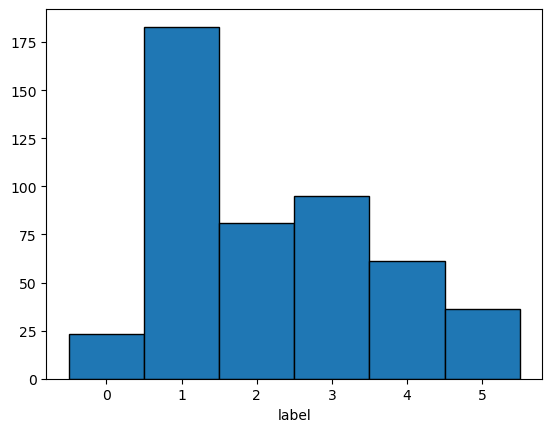

In [8]:
ds.label.plot.hist(bins=np.arange(-0.5, 6.5, 1), edgecolor='black')

In [124]:
for i in range(len(ds.image_data)):
    if np.isnan(ds.image_data[i]).any():
        print(f"Image {i} contains NaN values.")

# Fine-tune judge model for GOES data

## Functions

In [4]:
class GOESLabeledDataset(Dataset):
    """Dataset for manually labeled GOES images stored in netCDF format"""
    def __init__(self, labeled_netcdf_path):
        self.netcdf_path = labeled_netcdf_path
        
        # Load the netCDF dataset
        with xr.open_dataset(labeled_netcdf_path) as ds:
            # Load data into memory to avoid file access issues
            self.images = ds.image_data.values  # Shape: (n_samples, 4, 128, 128)
            self.labels = ds.label.values       # Shape: (n_samples,)
            self.metadata = {
                'unique_ids': ds.unique_id.values,
                'datetimes': ds.datetime.values,
                'lat_mid': ds.lat_mid.values,
                'lon_mid': ds.lon_mid.values,
                'class_names': ds.class_name.values
            }
        
        print(f"Loaded {len(self.images)} samples from {labeled_netcdf_path}")
        
    def __len__(self):
        return len(self.images)
    
    def __getitem__(self, idx):
        image = self.images[idx] # Shape: (4, 128, 128)
        label = self.labels[idx]
        
        # Debug checks
        if np.isnan(image).any():
            print(f"NaN found in image {idx}")
        if np.isinf(image).any():
            print(f"Inf found in image {idx}")
        
        return torch.FloatTensor(image), torch.LongTensor([label]).squeeze()
    
    def get_sample_info(self, idx):
        """Get metadata for a specific sample"""
        return {
            'unique_id': self.metadata['unique_ids'][idx],
            'datetime': self.metadata['datetimes'][idx],
            'lat_mid': self.metadata['lat_mid'][idx],
            'lon_mid': self.metadata['lon_mid'][idx],
            'class_name': self.metadata['class_names'][idx]
        }
    
    def get_class_distribution(self):
        """Get the distribution of classes in the dataset"""
        class_names = ['Solid stratus', 'Closed MCC', 'Open MCC', 'Disorganized MCC', 'Clustered Cu', 'Suppressed Cu']
        
        print("Class distribution:")
        print("-" * 40)
        for class_idx in range(6):
            count = (self.labels == class_idx).sum()
            percentage = 100 * count / len(self.labels)
            print(f"{class_names[class_idx]}: {count} ({percentage:.1f}%)")
        
        return {class_idx: (self.labels == class_idx).sum() for class_idx in range(6)}

def visualize_labeled_data(netcdf_path, num_samples=5):
    """Visualize some labeled samples from the netCDF file"""
    with xr.open_dataset(netcdf_path) as ds:
        n_samples = min(num_samples, len(ds.sample))
        
        fig, axes = plt.subplots(n_samples, 3, figsize=(16, 4*n_samples))
        if n_samples == 1:
            axes = axes.reshape(1, -1)
            
        class_names = ['Solid stratus', 'Closed MCC', 'Open MCC', 'Disorganized MCC', 'Clustered Cu', 'Suppressed Cu']
        
        for i in range(n_samples):
            image = ds.image_data[i].values
            label = ds.label[i].item()
            class_name = class_names[int(label)]
            datetime_str = pd.to_datetime(ds.datetime[i].values).strftime('%Y-%m-%d %H:%M')
            lat = ds.lat_mid[i].item()
            lon = ds.lon_mid[i].item()
            
            # COD channel
            axes[i, 0].imshow(image[3], vmax=1, cmap='Greys_r')
            axes[i, 0].set_title('COD Channel')
            axes[i, 0].axis('off')
            
            # BT channel
            axes[i, 1].imshow(image[2], vmax=1, cmap='Greys')
            axes[i, 1].set_title('BT Ch14')
            axes[i, 1].axis('off')
            
            # RGB composite
            rgb_image = np.zeros((128, 128, 3))
            for j in range(3):
                rgb_image[:, :, j] = image[j]
            axes[i, 2].imshow(rgb_image)
            axes[i, 2].set_title('RGB Composite')
            axes[i, 2].axis('off')
            
            # Add title with info
            title = f"Sample {i}: {label} {class_name}\n{datetime_str}, Lat {lat:.1f}°, Lon {lon:.1f}°"
            axes[i, 0].text(-10, 64, title, rotation=90, ha='right', va='center', fontsize=10)
            
        plt.tight_layout()
        plt.show()
        
        # Print summary statistics
        print(f"\nDataset summary:")
        print(f"Total samples: {len(ds.sample)}")
        print(f"Class distribution:")
        for class_idx, class_name in enumerate(class_names):
            count = (ds.label.values == class_idx).sum()
            percentage = 100 * count / len(ds.sample)
            print(f"  {class_name}: {count} ({percentage:.1f}%)")

In [5]:
def fine_tune_for_goes(model, labeled_nc_path, num_epochs=20, learning_rate=1e-5, batch_size=8, validation_split=0.2, save_best_model=True, model_save_path='finetuned_goes_model.pth'):
    """
    Fine-tune the MODIS-trained model on manually labeled GOES data
    
    Args:
        model: The pre-trained model to fine-tune
        labeled_nc_path: Path to CSV file with manually labeled data
        num_epochs: Number of training epochs
        learning_rate: Learning rate for fine-tuning
        batch_size: Batch size for training
        validation_split: Fraction of data to use for validation
        save_best_model: Whether to save the best model based on validation accuracy
        model_save_path: Path to save the best model
    """
    
    print("Setting up fine-tuning...")
    print(f"Labeled data: {labeled_nc_path}")
    print(f"Epochs: {num_epochs}, LR: {learning_rate}, Batch size: {batch_size}")
    
    # Create dataset
    dataset = GOESLabeledDataset(labeled_nc_path)
    
    if len(dataset) == 0:
        print("No labeled data found!")
        return model, None
    
    print(f"Found {len(dataset)} labeled samples")
    
    # Split into train/validation
    # Get all labels for stratification
    all_labels = [dataset.labels[i] for i in range(len(dataset))]

    # Create indices for stratified split
    indices = list(range(len(dataset)))
    train_indices, val_indices = train_test_split(
        indices, 
        test_size=validation_split,
        stratify=all_labels,
        random_state=42
    )

    # Create subset datasets using the stratified indices
    train_dataset = torch.utils.data.Subset(dataset, train_indices)
    val_dataset = torch.utils.data.Subset(dataset, val_indices) if val_indices else None
    
    # Create data loaders
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2)
    
    print(f"Training samples: {len(train_dataset)}")
    print(f"Validation samples: {len(val_dataset)}")
    
    # Freeze early layers, only train final classifier
    for param in model.parameters():
        param.requires_grad = False
    
    # Unfreeze final layers
    for param in model.fc.parameters():
        param.requires_grad = True
    
    # Setup optimizer and loss
    optimizer = torch.optim.Adam(model.fc.parameters(), lr=learning_rate, weight_decay=1e-6)
    criterion = nn.CrossEntropyLoss()
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.5)
    
    # Training metrics
    train_losses = []
    train_accuracies = []
    val_losses = []
    val_accuracies = []
    
    # Best model tracking - keep 0-based throughout
    best_val_accuracy = 0.0
    best_model_state = None
    best_epoch = 0  # 0-based epoch index

    # Training loop
    device = next(model.parameters()).device
    
    for epoch in range(1, num_epochs + 1):
        # Training phase
        model.train()
        train_loss = 0.0
        train_correct = 0
        train_total = 0
        
        print(f"\nEpoch {epoch}/{num_epochs}")  # Display as 1-based for humans
        print("-" * 30)
        
        for batch_idx, (images, labels) in enumerate(train_loader):
            images = images.to(device)
            labels = labels.to(device)
            
            # Forward pass
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            
            # Backward pass
            loss.backward()
            optimizer.step()
            
            # Statistics
            train_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            train_total += labels.size(0)
            train_correct += (predicted == labels).sum().item()
            
            if batch_idx % 5 == 0:
                print(f"Batch {batch_idx+1}/{len(train_loader)}, Loss: {loss.item():.4f}")
        
        # Calculate training metrics
        epoch_train_loss = train_loss / len(train_loader)
        epoch_train_acc = 100 * train_correct / train_total
        
        train_losses.append(epoch_train_loss)
        train_accuracies.append(epoch_train_acc)
        
        print(f"Training Loss: {epoch_train_loss:.4f}, Training Accuracy: {epoch_train_acc:.2f}%")
        
        # Validation phase
        model.eval()
        val_loss = 0.0
        val_correct = 0
        val_total = 0
        
        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(device)
                labels = labels.to(device)
                
                outputs = model(images)
                loss = criterion(outputs, labels)
                
                val_loss += loss.item()
                _, predicted = torch.max(outputs.data, 1)
                val_total += labels.size(0)
                val_correct += (predicted == labels).sum().item()
        
        epoch_val_loss = val_loss / len(val_loader)
        current_val_accuracy = 100 * val_correct / val_total
        
        val_losses.append(epoch_val_loss)
        val_accuracies.append(current_val_accuracy)
        
        print(f"Validation Loss: {epoch_val_loss:.4f}, Validation Accuracy: {current_val_accuracy:.2f}%")
        
        # Save best model based on validation accuracy
        if save_best_model and current_val_accuracy > best_val_accuracy:
            best_val_accuracy = current_val_accuracy
            best_model_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch  # Store 0-based epoch
            print(f"✓ New best model! Validation accuracy: {best_val_accuracy:.2f}% (Epoch {epoch})")  # Display as 1-based
            
            # SAVE IMMEDIATELY when we find a better model
            torch.save(best_model_state, model_save_path)
            print(f"✓ Best model saved to {model_save_path}")

        scheduler.step()

    print("\nFine-tuning complete!")
    
    # Load the best model state
    if save_best_model and best_model_state is not None:
        model.load_state_dict(best_model_state)
        print(f"Loaded best model from epoch {best_epoch} with validation accuracy: {best_val_accuracy:.2f}%")  # Display as 1-based
        
        # Save the best model
        torch.save(best_model_state, model_save_path)
        
        # Save metadata for the best model
        metadata = {
            'model_type': 'ResNet50d fine-tuned for GOES',
            'input_channels': 4,
            'num_classes': 6,
            'best_epoch': best_epoch,  # Store 0-based in metadata
            'best_validation_accuracy': best_val_accuracy,
            'total_epochs': num_epochs,
            'fine_tuned_date': pd.Timestamp.now().strftime('%Y-%m-%d %H:%M:%S'),
            'hyperparameters': {
                'learning_rate': learning_rate,
                'batch_size': batch_size,
                'validation_split': validation_split
            }
        }
        
        metadata_path = model_save_path.replace('.pth', '_metadata.json')
        with open(metadata_path, 'w') as f:
            json.dump(metadata, f, indent=2)
        
        print(f"Best model saved to: {model_save_path}")
        print(f"Metadata saved to: {metadata_path}")
    
    # Plot training curves
    plt.figure(figsize=(12, 4))
    
    plt.subplot(1, 2, 1)
    plt.plot(np.arange(1, num_epochs+1), train_losses, label='Train Loss', color='blue')
    if val_losses:
        plt.plot(np.arange(1, num_epochs+1), val_losses, label='Val Loss', color='red')
    if save_best_model and best_epoch >= 0:
        plt.axvline(x=best_epoch, color='green', linestyle='--', alpha=0.7, label=f'Best Model (Epoch {best_epoch})')  # Use 0-based for line position, 1-based for label
    plt.title('Training Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)
    
    plt.subplot(1, 2, 2)
    plt.plot(np.arange(1, num_epochs+1), train_accuracies, label='Train Acc', color='blue')
    if val_accuracies:
        plt.plot(np.arange(1, num_epochs+1), val_accuracies, label='Val Acc', color='red')
    if save_best_model and best_epoch >= 0:
        plt.axvline(x=best_epoch, color='green', linestyle='--', alpha=0.7, label=f'Best Model (Epoch {best_epoch})')  # Use 0-based for line position, 1-based for label
    plt.title('Training Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy (%)')
    plt.legend()
    plt.grid(True)
    
    plt.tight_layout()
    plt.show()
    
    dataset.get_class_distribution()
    
    return model, val_dataset


def save_finetuned_model(model, save_path, metadata=None):
    """Save the fine-tuned model with metadata"""
    
    # Save model state dict
    torch.save(model.state_dict(), save_path)
    
    # Save metadata
    if metadata is None:
        metadata = {
            'model_type': 'ResNet50d fine-tuned for GOES',
            'input_channels': 4,
            'num_classes': 6,
            'fine_tuned_date': pd.Timestamp.now().strftime('%Y-%m-%d %H:%M:%S')
        }
    
    metadata_path = save_path.replace('.pth', '_metadata.json')
    with open(metadata_path, 'w') as f:
        json.dump(metadata, f, indent=2)
    
    print(f"Model saved to: {save_path}")
    print(f"Metadata saved to: {metadata_path}")


def evaluate_finetuned_model(model, dataset_or_path, class_names=None):
    """Evaluate the fine-tuned model on labeled data"""
    
    if class_names is None:
        class_names = ['Solid stratus', 'Closed MCC', 'Open MCC', 'Disorganized MCC', 'Clustered Cu', 'Suppressed Cu']
    
        # Check if input is a dataset object or file path
    if isinstance(dataset_or_path, torch.utils.data.Dataset):
        dataset = dataset_or_path
        print(f"Evaluating on provided dataset with {len(dataset)} samples")
    else:
        dataset = GOESLabeledDataset(dataset_or_path)
        print(f"Evaluating on full dataset from {dataset_or_path} with {len(dataset)} samples")
        
    dataloader = DataLoader(dataset, batch_size=8, shuffle=False)
    
    model.eval()
    device = next(model.parameters()).device
    
    all_predictions = []
    all_labels = []
    
    with torch.no_grad():
        for images, labels in dataloader:
            images = images.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            
            all_predictions.extend(predicted.cpu().numpy())
            all_labels.extend(labels.numpy())
    
    # Calculate accuracy
    accuracy = 100 * np.mean(np.array(all_predictions) == np.array(all_labels))
    print(f"Overall Accuracy: {accuracy:.2f}%")
    
    # Per-class accuracy
    print("\nPer-class accuracy:")
    print("-" * 40)
    class_acc_list = []
    for class_idx in range(len(class_names)):
        mask = np.array(all_labels) == class_idx
        if mask.sum() > 0:
            class_acc = 100 * np.mean(np.array(all_predictions)[mask] == class_idx)
            count = mask.sum()
            print(f"{class_names[class_idx]}: {class_acc:.1f}% ({count} samples)")
            class_acc_list.append((class_names[class_idx], class_acc, count))

    accuracy_equal_weighted = np.mean([acc for _, acc, _ in class_acc_list])
    print(f"\nEqual-weighted Accuracy: {accuracy_equal_weighted:.2f}%")

    # compute fscore for each class
    from sklearn.metrics import f1_score
    fscore = f1_score(all_labels, all_predictions, average=None)
    print("\nF1 Score per class:")
    for class_idx in range(len(class_names)):
        print(f"{class_names[class_idx]}: {fscore[class_idx]:.3f}")
    
    return all_predictions, all_labels


def plot_confusion_matrix(y_true, y_pred, class_names=None, normalize=True, title='Confusion Matrix GOES'):
    """Plot a confusion matrix"""
    from sklearn.metrics import confusion_matrix
    import matplotlib.pyplot as plt
    import seaborn as sns
    
    if class_names is None:
        class_names = ['Solid stratus', 'Closed MCC', 'Open MCC', 'Disorganized MCC', 'Clustered Cu', 'Suppressed Cu']
    
    cm = confusion_matrix(y_true, y_pred)
    
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        fmt = '.2f'
        title += ' (Normalized)'
    else:
        fmt = 'd'
    
    plt.figure(figsize=(7, 6))
    sns.heatmap(cm, annot=True, fmt=fmt, cmap='Blues', 
                xticklabels=class_names, yticklabels=class_names,
                cbar_kws={'label': 'Count' if not normalize else 'Proportion'})
    plt.title(title)
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()
    
    return cm

## Hyperparameter search and cross validation of fine-tuning

Loop through hyperparameter combinations and perform k-fold cross-validation to find the best set of hyperparameters for fine-tuning the judge model on GOES data. <br>
The search results, including the best hyperparameters and their corresponding performance metrics, are logged to a file for later analysis.

In [ ]:
import logging
import sys
from datetime import datetime

def setup_logging(log_file=None):
    """Setup logging to both file and console"""
    if log_file is None:
        timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
        log_file = f'hyperparameter_search_{timestamp}.log'
    
    # Create logger
    logger = logging.getLogger('hyperparameter_search')
    logger.setLevel(logging.INFO)
    
    # Clear existing handlers
    logger.handlers = []
    
    # Create formatter
    formatter = logging.Formatter('%(asctime)s - %(levelname)s - %(message)s')
    
    # File handler
    file_handler = logging.FileHandler(log_file)
    file_handler.setLevel(logging.INFO)
    file_handler.setFormatter(formatter)
    logger.addHandler(file_handler)
    
    # Console handler
    console_handler = logging.StreamHandler(sys.stdout)
    console_handler.setLevel(logging.INFO)
    console_handler.setFormatter(formatter)
    logger.addHandler(console_handler)
    
    return logger, log_file

def hyperparameter_grid_search_with_logging(model_path, labeled_nc_path, param_grid, k_folds=5, random_state=42, log_file=None):
    """
    Perform grid search over hyperparameters using cross-validation with comprehensive logging
    
    Args:
        model_path: Path to pre-trained model weights
        labeled_nc_path: Path to labeled netCDF data
        param_grid: Dictionary of hyperparameters to search over
        k_folds: Number of cross-validation folds
        random_state: Random seed for reproducibility
        log_file: Optional log file path. If None, auto-generated with timestamp
    
    Returns:
        dict: Best hyperparameters and results
    """
    
    from itertools import product
    import json
    
    # Setup logging
    logger, log_path = setup_logging(log_file)
    
    logger.info("=" * 80)
    logger.info("HYPERPARAMETER GRID SEARCH STARTED")
    logger.info("=" * 80)
    logger.info(f"Model path: {model_path}")
    logger.info(f"Labeled data path: {labeled_nc_path}")
    logger.info(f"Parameter grid: {param_grid}")
    logger.info(f"Cross-validation folds: {k_folds}")
    logger.info(f"Random state: {random_state}")
    logger.info(f"Log file: {log_path}")
    
    # Generate all parameter combinations
    param_names = list(param_grid.keys())
    param_values = list(param_grid.values())
    param_combinations = list(product(*param_values))
    
    logger.info(f"Testing {len(param_combinations)} hyperparameter combinations")
    logger.info(f"Total estimated experiments: {len(param_combinations) * k_folds}")
    
    best_score = 0.0
    best_params = None
    all_results = []
    
    for i, param_combo in enumerate(param_combinations):
        params = dict(zip(param_names, param_combo))
        
        logger.info("=" * 60)
        logger.info(f"COMBINATION {i+1}/{len(param_combinations)}")
        logger.info("=" * 60)
        logger.info(f"Parameters: {params}")
        
        # Run cross-validation for this parameter combination
        try:
            start_time = datetime.now()
            
            cv_results = cross_validate_fine_tuning_with_logging(
                model_path=model_path,
                labeled_nc_path=labeled_nc_path,
                k_folds=k_folds,
                num_epochs=params['num_epochs'],
                learning_rate=params['learning_rate'],
                batch_size=params['batch_size'],
                random_state=random_state,
                logger=logger
            )
            
            end_time = datetime.now()
            duration = (end_time - start_time).total_seconds()
            
            mean_accuracy = cv_results['summary']['mean_accuracy']
            std_accuracy = cv_results['summary']['std_accuracy']
            
            result = {
                'params': params,
                'mean_accuracy': mean_accuracy,
                'std_accuracy': std_accuracy,
                'duration_seconds': duration,
                'cv_results': cv_results
            }
            all_results.append(result)
            
            logger.info(f"RESULT: {mean_accuracy:.2f} ± {std_accuracy:.2f}% (Duration: {duration:.1f}s)")
            
            # Update best parameters
            if mean_accuracy > best_score:
                best_score = mean_accuracy
                best_params = params.copy()
                logger.info(f"✓ NEW BEST PARAMETERS! Score: {best_score:.2f}%")
                
                # Save best results immediately
                best_result_file = log_path.replace('.log', '_best_params.json')
                with open(best_result_file, 'w') as f:
                    json.dump({
                        'best_params': best_params,
                        'best_score': best_score,
                        'timestamp': datetime.now().isoformat()
                    }, f, indent=2)
                logger.info(f"Best parameters saved to: {best_result_file}")
            
        except Exception as e:
            logger.error(f"ERROR with parameters {params}: {str(e)}")
            logger.error(f"Exception type: {type(e).__name__}")
            import traceback
            logger.error(f"Traceback: {traceback.format_exc()}")
            continue
    
    # Final summary
    logger.info("=" * 80)
    logger.info("HYPERPARAMETER SEARCH COMPLETED")
    logger.info("=" * 80)
    logger.info(f"Best parameters: {best_params}")
    logger.info(f"Best CV score: {best_score:.2f}%")
    
    # Sort results by mean accuracy
    all_results.sort(key=lambda x: x['mean_accuracy'], reverse=True)
    
    logger.info("\nTop 5 parameter combinations:")
    for i, result in enumerate(all_results[:5]):
        logger.info(f"{i+1}. {result['params']} -> {result['mean_accuracy']:.2f} ± {result['std_accuracy']:.2f}% ({result['duration_seconds']:.1f}s)")
    
    # Save complete results to JSON file
    results_file = log_path.replace('.log', '_complete_results.json')
    final_results = {
        'best_params': best_params,
        'best_score': best_score,
        'all_results': all_results,
        'search_completed': datetime.now().isoformat(),
        'total_combinations': len(param_combinations),
        'successful_combinations': len(all_results)
    }
    
    with open(results_file, 'w') as f:
        json.dump(final_results, f, indent=2, default=str)
    
    logger.info(f"Complete results saved to: {results_file}")
    logger.info(f"Log saved to: {log_path}")
    
    return final_results

def cross_validate_fine_tuning_with_logging(model_path, labeled_nc_path, k_folds=5, num_epochs=20, 
                                          learning_rate=1e-4, batch_size=8, random_state=42, logger=None):
    """
    Modified cross-validation function with logging support
    """
    
    if logger is None:
        logger = logging.getLogger('hyperparameter_search')
    
    logger.info(f"Starting {k_folds}-fold cross-validation...")
    
    # Load dataset
    dataset = GOESLabeledDataset(labeled_nc_path)
    all_labels = dataset.labels
    
    logger.info(f"Dataset loaded: {len(dataset)} samples")
    
    # Setup stratified k-fold
    skf = StratifiedKFold(n_splits=k_folds, shuffle=True, random_state=random_state)
    
    # Results storage
    cv_results = {
        'fold_accuracies': [],
        'fold_losses': [],
        'per_class_accuracies': [],
        'fold_histories': []
    }
    
    class_names = ['Solid stratus', 'Closed MCC', 'Open MCC', 'Disorganized MCC', 'Clustered Cu', 'Suppressed Cu']
    
    # Device setup
    device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
    logger.info(f"Using device: {device}")
    
    for fold, (train_indices, val_indices) in enumerate(skf.split(range(len(dataset)), all_labels)):
        logger.info(f"FOLD {fold + 1}/{k_folds}")
        logger.info("-" * 40)
        
        fold_start_time = datetime.now()
        
        # Create fresh model for each fold
        model = timm.create_model('resnet50d', pretrained=False)
        model.conv1 = nn.Conv2d(4, 64, kernel_size=7, stride=2, padding=3, bias=False)
        model.fc = nn.Linear(2048, 6)
        model = model.to(device)
        
        # Load pre-trained weights
        weights = torch.load(model_path, map_location=device)
        model.load_state_dict(weights)
        
        # Create fold datasets
        train_dataset = torch.utils.data.Subset(dataset, train_indices)
        val_dataset = torch.utils.data.Subset(dataset, val_indices)
        
        # Create data loaders
        train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)
        val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2)
        
        logger.info(f"Training samples: {len(train_dataset)}, Validation samples: {len(val_dataset)}")
        
        # Freeze early layers, only train final classifier
        for param in model.parameters():
            param.requires_grad = False
        for param in model.fc.parameters():
            param.requires_grad = True
        
        # Setup optimizer and loss
        optimizer = torch.optim.Adam(model.fc.parameters(), lr=learning_rate, weight_decay=1e-6)
        criterion = nn.CrossEntropyLoss()
        scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.5)
        
        # Training metrics for this fold
        fold_train_losses = []
        fold_val_losses = []
        fold_val_accuracies = []
        best_val_acc = 0.0
        
        # Training loop for this fold
        for epoch in range(num_epochs):
            epoch_start_time = datetime.now()
            
            # Training phase
            model.train()
            train_loss = 0.0
            
            for batch_idx, (images, labels) in enumerate(train_loader):
                images = images.to(device)
                labels = labels.to(device)
                
                optimizer.zero_grad()
                outputs = model(images)
                loss = criterion(outputs, labels)
                loss.backward()
                optimizer.step()
                
                train_loss += loss.item()
            
            # Validation phase
            model.eval()
            val_loss = 0.0
            val_correct = 0
            val_total = 0
            
            with torch.no_grad():
                for images, labels in val_loader:
                    images = images.to(device)
                    labels = labels.to(device)
                    
                    outputs = model(images)
                    loss = criterion(outputs, labels)
                    
                    val_loss += loss.item()
                    _, predicted = torch.max(outputs, 1)
                    val_total += labels.size(0)
                    val_correct += (predicted == labels).sum().item()
            
            epoch_train_loss = train_loss / len(train_loader)
            epoch_val_loss = val_loss / len(val_loader)
            epoch_val_acc = 100 * val_correct / val_total
            
            fold_train_losses.append(epoch_train_loss)
            fold_val_losses.append(epoch_val_loss)
            fold_val_accuracies.append(epoch_val_acc)
            
            if epoch_val_acc > best_val_acc:
                best_val_acc = epoch_val_acc
            
            epoch_duration = (datetime.now() - epoch_start_time).total_seconds()
            
            if epoch % 5 == 0 or epoch == num_epochs - 1:
                logger.info(f"  Epoch {epoch}/{num_epochs}: Val Loss={epoch_val_loss:.4f}, Val Acc={epoch_val_acc:.2f}%, Time={epoch_duration:.1f}s")
            
            scheduler.step()
        
        fold_duration = (datetime.now() - fold_start_time).total_seconds()
        
        # Final evaluation for this fold using best accuracy from training
        logger.info(f"Fold {fold + 1} completed: Best Val Acc={best_val_acc:.2f}%, Duration={fold_duration:.1f}s")
        
        # Store fold results
        cv_results['fold_accuracies'].append(best_val_acc)
        cv_results['fold_losses'].append(min(fold_val_losses))
        cv_results['fold_histories'].append({
            'train_losses': fold_train_losses,
            'val_losses': fold_val_losses,
            'val_accuracies': fold_val_accuracies
        })
    
    # Compute summary statistics
    mean_accuracy = np.mean(cv_results['fold_accuracies'])
    std_accuracy = np.std(cv_results['fold_accuracies'])
    mean_loss = np.mean(cv_results['fold_losses'])
    std_loss = np.std(cv_results['fold_losses'])
    
    logger.info(f"Cross-validation complete:")
    logger.info(f"  Mean Accuracy: {mean_accuracy:.2f} ± {std_accuracy:.2f}%")
    logger.info(f"  Mean Loss: {mean_loss:.4f} ± {std_loss:.4f}")
    logger.info(f"  Fold Accuracies: {[f'{acc:.2f}%' for acc in cv_results['fold_accuracies']]}")
    
    # Add summary statistics to results
    cv_results['summary'] = {
        'mean_accuracy': mean_accuracy,
        'std_accuracy': std_accuracy,
        'mean_loss': mean_loss,
        'std_loss': std_loss
    }
    
    return cv_results

In [ ]:
param_grid = {
    'learning_rate': [5e-5, 1e-4, 5e-4],
    'batch_size': [4, 8, 16],
    'num_epochs': [15, 20, 30]
}

# Run grid search with logging
grid_search_results = hyperparameter_grid_search_with_logging(
    model_path='/home/jmayer/ACI_research/YuanyuanWu-NJU-Cloud-morphology-dataset/Model_judge/64epochs_accuracy0.91456.pth',
    labeled_nc_path='labeled_goes_data.nc',
    param_grid=param_grid,
    k_folds=3,  # Reduced for faster search
    random_state=42,
    log_file='hyperparameter_search.log'
)

## Fine-tune model

Found 479 labeled samples
Using device: cpu


/tmp/ipykernel_3942230/394620286.py:26: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  weights = torch.load(model_path, map_location=device)


Loaded pre-trained MODIS model
Starting fine-tuning...
Setting up fine-tuning...
Labeled data: labeled_goes_data.nc
Epochs: 30, LR: 0.0005, Batch size: 16
Loaded 479 samples from labeled_goes_data.nc
Found 479 labeled samples
Training samples: 383
Validation samples: 96

Epoch 1/30
------------------------------
Batch 1/24, Loss: 1.4129
Batch 6/24, Loss: 0.9516
Batch 11/24, Loss: 0.3870
Batch 16/24, Loss: 0.4186
Batch 21/24, Loss: 1.0731
Training Loss: 1.0036, Training Accuracy: 67.10%
Validation Loss: 0.8271, Validation Accuracy: 71.88%
✓ New best model! Validation accuracy: 71.88% (Epoch 1)
✓ Best model saved to finetuned_goes_model.pth

Epoch 2/30
------------------------------
Batch 1/24, Loss: 0.6611
Batch 6/24, Loss: 0.4402
Batch 11/24, Loss: 0.4524
Batch 16/24, Loss: 0.8689
Batch 21/24, Loss: 0.7473
Training Loss: 0.7403, Training Accuracy: 72.06%
Validation Loss: 0.7722, Validation Accuracy: 71.88%

Epoch 3/30
------------------------------
Batch 1/24, Loss: 0.7633
Batch 6/24, 

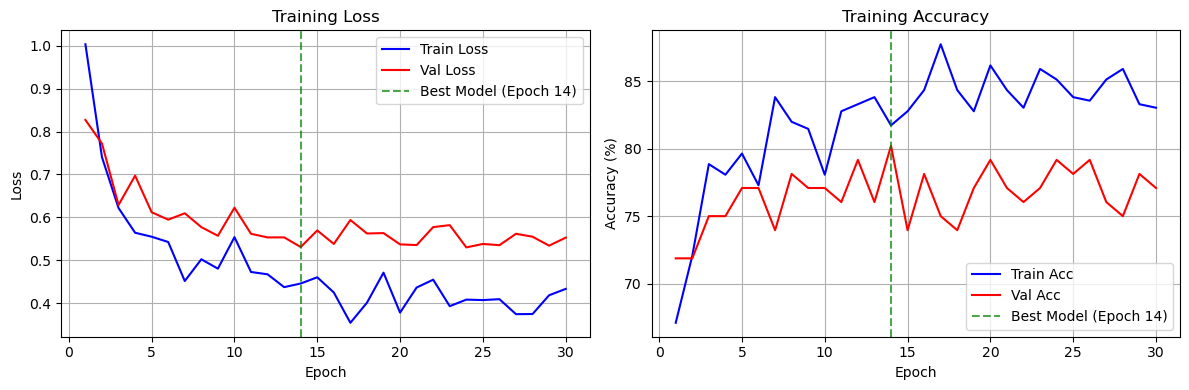

Class distribution:
----------------------------------------
Solid stratus: 23 (4.8%)
Closed MCC: 183 (38.2%)
Open MCC: 81 (16.9%)
Disorganized MCC: 95 (19.8%)
Clustered Cu: 61 (12.7%)
Suppressed Cu: 36 (7.5%)
Evaluation results saved to: finetuned_goes_model_evaluation_20260126_181613.txt


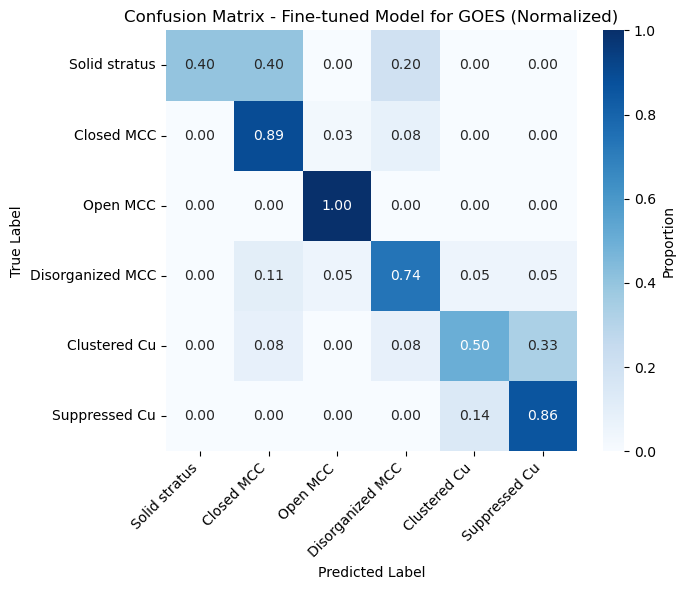

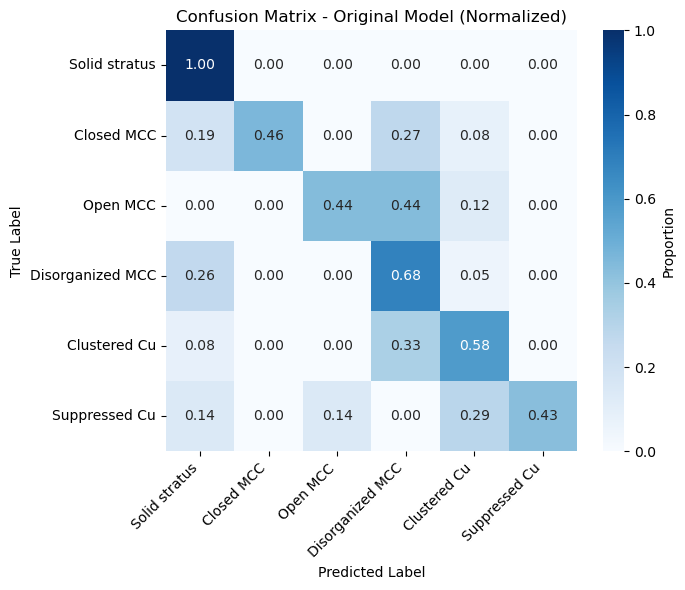

In [10]:
# Example usage of the fine-tuning functions
save_path = 'labeled_goes_data.nc'

# Check if we have labeled data
if os.path.exists(save_path):
    with xr.open_dataset(save_path) as ds:
        num_samples = len(ds.sample)
    print(f"Found {num_samples} labeled samples")
    
    if num_samples >= 5:  # Need at least a few samples
        # Define device
        device_num = '0'  # Change this to your GPU number or 'cpu'
        device = torch.device(f'cuda:{device_num}' if torch.cuda.is_available() and device_num != 'cpu' else 'cpu')
        print(f"Using device: {device}")
        
        # Load the pre-trained modelß
        class_names = ['Solid stratus', 'Closed MCC', 'Open MCC', 'Disorganized MCC', 'Clustered Cu', 'Suppressed Cu']
        model_path = '/home/jmayer/ACI_research/YuanyuanWu-NJU-Cloud-morphology-dataset/Model_judge/64epochs_accuracy0.91456.pth'
        
        model = timm.create_model('resnet50d', pretrained=False)
        model.conv1 = nn.Conv2d(4, 64, kernel_size=7, stride=2, padding=3, bias=False)
        model.fc = nn.Linear(2048, 6)
        model = model.to(device)
        
        # Load pre-trained weights
        weights = torch.load(model_path, map_location=device)
        model.load_state_dict(weights)
        original_model = copy.deepcopy(model)  # Keep a copy of the original model for comparison
        print("Loaded pre-trained MODIS model")
        
        # Visualize some labeled samples before training
        #print("\nVisualizating labeled samples:")
        #visualize_labeled_data(save_path, num_samples=3)
        
        # Fine-tune the model
        # Fine-tune the model
        print("Starting fine-tuning...")
        finetuned_model, val_dataset = fine_tune_for_goes(
            model=model,
            labeled_nc_path=save_path,
            num_epochs=30,
            learning_rate=5e-4,
            batch_size=16,
            validation_split=0.2,
            save_best_model=True,
            model_save_path='finetuned_goes_model.pth'
        )

        # Evaluate the fine-tuned model (which is now the best model)
        #print("\nEvaluating best fine-tuned model on VALIDATION dataset only:")
        #evaluate_finetuned_model(finetuned_model, val_dataset, class_names)
        #
        #print("-"*40)
        #print("-"*40)
        #print("\nEvaluating original model on VALIDATION dataset only:")
        #evaluate_finetuned_model(original_model, val_dataset, class_names)

        # Create a timestamp for unique filename
        timestamp = pd.Timestamp.now().strftime("%Y%m%d_%H%M%S")
        output_file = f'finetuned_goes_model_evaluation_{timestamp}.txt'

        # Capture output to both file and console
        with open(output_file, 'w') as f:
            # Redirect stdout to capture print statements
            with redirect_stdout(f):
                # Evaluate the fine-tuned model
                print("\nEvaluating best fine-tuned model (on VALIDATION dataset only):")
                ft_predictions, ft_labels = evaluate_finetuned_model(finetuned_model, val_dataset, class_names)

                print("-"*40)
                print("-"*40)
                print("\nEvaluating original model (on VALIDATION dataset only):")
                orig_predictions, orig_labels = evaluate_finetuned_model(original_model, val_dataset, class_names)

        print(f"Evaluation results saved to: {output_file}")

        plot_confusion_matrix(ft_labels, ft_predictions, class_names=class_names, normalize=True, title='Confusion Matrix - Fine-tuned Model for GOES')
        plot_confusion_matrix(orig_labels, orig_predictions, class_names=class_names, normalize=True, title='Confusion Matrix - Original Model')
        
    else:
        print("Need at least 5 labeled samples for fine-tuning. Please label more data first.")
else:
    print(f"No labeled data found at {save_path}. Please run the labeling tool first.")

## compare predictions before and after fine-tuning

In [9]:
# evaluate some samples from the labeled dataset
def load_model(model_path):
    """Load the fine-tuned model from disk"""
    device_num = '0'  # Change this to your GPU number or 'cpu'
    device = torch.device(f'cuda:{device_num}' if torch.cuda.is_available() and device_num != 'cpu' else 'cpu')
    
    model = timm.create_model('resnet50d', pretrained=False)
    model.conv1 = nn.Conv2d(4, 64, kernel_size=7, stride=2, padding=3, bias=False)
    model.fc = nn.Linear(2048, 6)
    model = model.to(device)
    
    weights = torch.load(model_path, map_location=device)
    model.load_state_dict(weights)
    model.eval()
    
    print(f"Loaded fine-tuned model from {model_path}")
    return model

original_model_path = '/home/jmayer/ACI_research/YuanyuanWu-NJU-Cloud-morphology-dataset/Model_judge/64epochs_accuracy0.91456.pth'
original_model = load_model(original_model_path)

fine_tuned_model_path = 'finetuned_goes_model.pth'
fine_tuned_model = load_model(fine_tuned_model_path)

/tmp/ipykernel_3376102/487094570.py:12: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  weights = torch.load(model_path, map_location=device)


Loaded fine-tuned model from /home/jmayer/ACI_research/YuanyuanWu-NJU-Cloud-morphology-dataset/Model_judge/64epochs_accuracy0.91456.pth
Loaded fine-tuned model from finetuned_goes_model.pth


In [ ]:
dataset = GOESLabeledDataset(save_path)

for i in np.random.choice(len(dataset), 5, replace=False):
    image_tensor, label_tensor = dataset[i]  # Unpack the tuple correctly

    # Add batch dimension since model expects batched input
    image_tensor = image_tensor.unsqueeze(0).to(device)  # Shape: (1, 4, 128, 128)

    # Now pass only the image tensor to the new model
    outputs = fine_tuned_model(image_tensor)
    _, predicted = torch.max(outputs.data, 1)

    outputs_original = original_model(image_tensor)
    _, predicted_original = torch.max(outputs_original.data, 1)

    plt.imshow(image_tensor[0][3].cpu().numpy(), cmap='Greys_r')
    plt.title(f"Predicted: {predicted.item()}, Original judge: {predicted_original.item()}, True: {label_tensor.item()}")
    plt.axis('off')
    print(outputs)
    print(outputs_original)
    plt.show()